# 🚨 Disaster Management System: End-to-End AI Pipeline
**Research Environment: Google Colab GPU**

This notebook contains the comprehensive, research-grade pipeline for the Unified Disaster Management System. It encompasses deep exploratory data analysis (EDA), temporal feature engineering, advanced hyperparameter tuning via Cross-Validation, and Explainable AI (SHAP) for critical risk prediction.

In [1]:
# Simulate Google Colab Environment Setup
# !pip install -q xgboost shap seaborn missingno
# from google.colab import drive
# drive.mount('/content/drive')


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import shap
import warnings
import missingno as msno

warnings.filterwarnings('ignore')
# High-quality visual style for research publication
plt.style.use('dark_background')
sns.set_palette("husl")
plt.rcParams['figure.dpi'] = 120


## 1. Data Ingestion & Integration

In [3]:
print("Loading Meteorological and Cyclone Datasets...")

# Load Rainfall Data
rain_df = pd.read_csv('../data/rainfall_manual_daily_odisha_od_2021_2025.csv', low_memory=False)
rain_df['Date'] = pd.to_datetime(rain_df['Data Acquisition Time'], format='mixed', dayfirst=True).dt.date
daily_rain = rain_df.groupby('Date')['Manual Daily Rainfall (mm)'].mean().reset_index()

# Load Cyclone Data (IBTrACS)
cyclone_df = pd.read_csv('../data/ibtracs.NI.list.v04r01.csv', skiprows=[1], low_memory=False)
cyclone_df['Date'] = pd.to_datetime(cyclone_df['ISO_TIME'], format='mixed').dt.date
cyclone_df['WMO_WIND'] = pd.to_numeric(cyclone_df['WMO_WIND'].replace(' ', np.nan), errors='coerce')
daily_wind = cyclone_df.groupby('Date')['WMO_WIND'].max().reset_index()

# Merge Datasets on Date
merged_df = pd.merge(daily_rain, daily_wind, on='Date', how='outer')
merged_df.sort_values('Date', inplace=True)
merged_df.set_index(pd.DatetimeIndex(merged_df['Date']), inplace=True)
merged_df.drop('Date', axis=1, inplace=True)

display(merged_df.head())


Loading Meteorological and Cyclone Datasets...


,Manual Daily Rainfall (mm),WMO_WIND
Date,,
1842-10-25,NaN,NaN
1842-10-26,NaN,NaN
1842-10-27,NaN,NaN
1842-10-28,NaN,NaN
1842-10-29,NaN,NaN


## 2. Deep Exploratory Data Analysis (EDA)

<Figure size 1200x480 with 0 Axes>

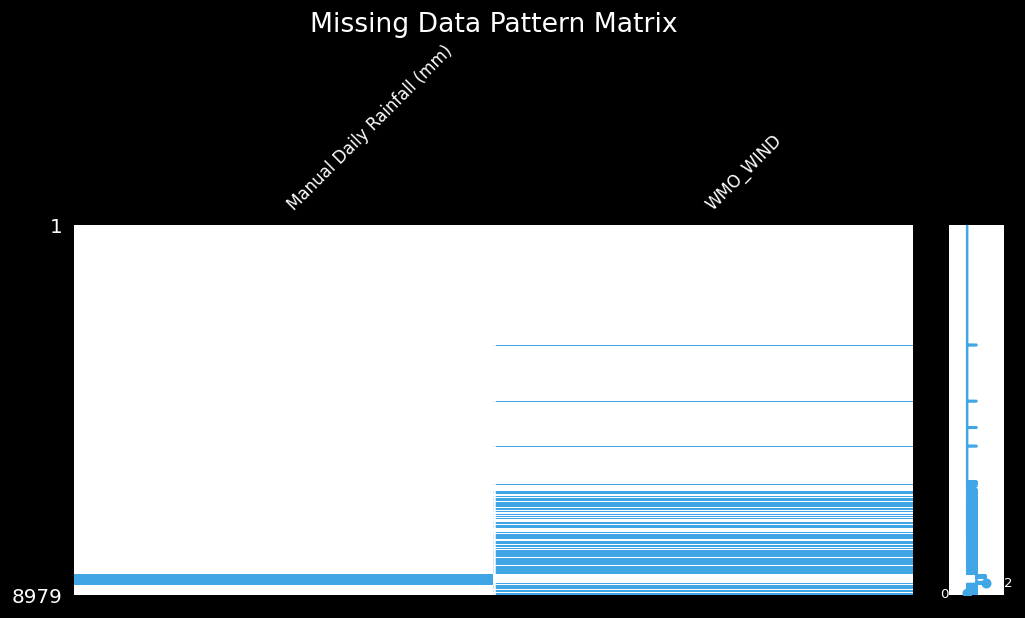

In [4]:
# 2.1 Missing Data Analysis
plt.figure(figsize=(10, 4))
msno.matrix(merged_df, figsize=(10, 4), color=(0.25, 0.65, 0.9), fontsize=10)
plt.title("Missing Data Pattern Matrix", fontsize=16)
plt.show()


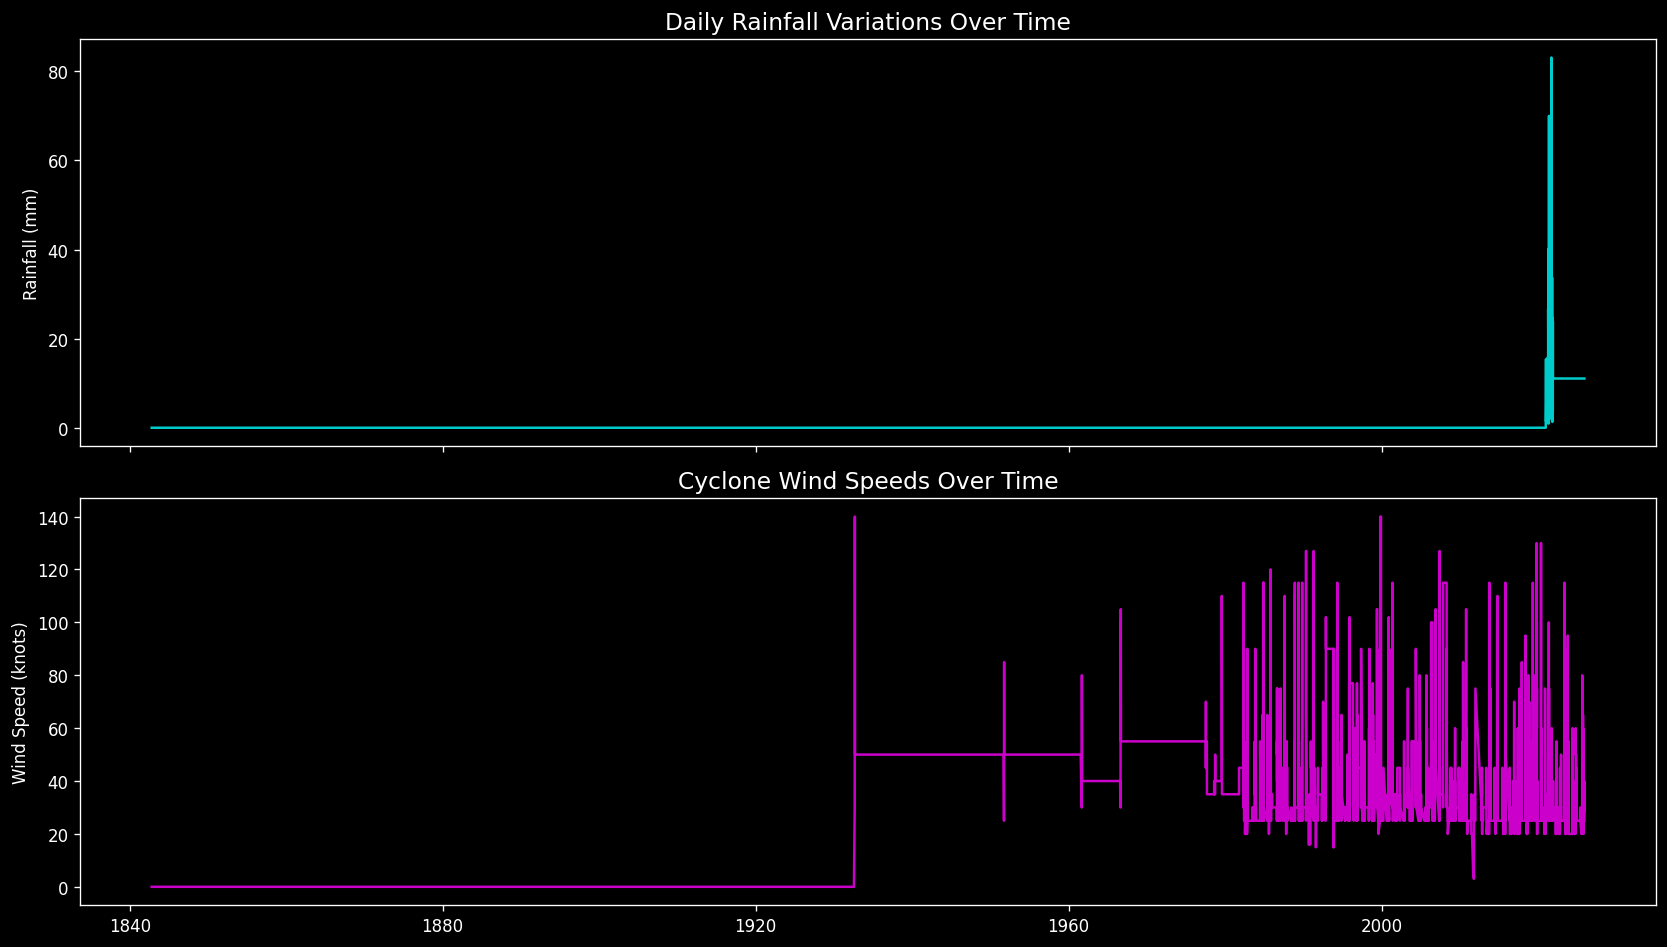

In [5]:
# Imputation Strategy
merged_df.ffill(inplace=True)
merged_df.fillna(0, inplace=True)

# 2.2 Time-Series Distributions
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(merged_df.index, merged_df['Manual Daily Rainfall (mm)'], color='cyan', alpha=0.8)
axes[0].set_title('Daily Rainfall Variations Over Time', fontsize=14)
axes[0].set_ylabel('Rainfall (mm)')

axes[1].plot(merged_df.index, merged_df['WMO_WIND'], color='magenta', alpha=0.8)
axes[1].set_title('Cyclone Wind Speeds Over Time', fontsize=14)
axes[1].set_ylabel('Wind Speed (knots)')

plt.tight_layout()
plt.show()


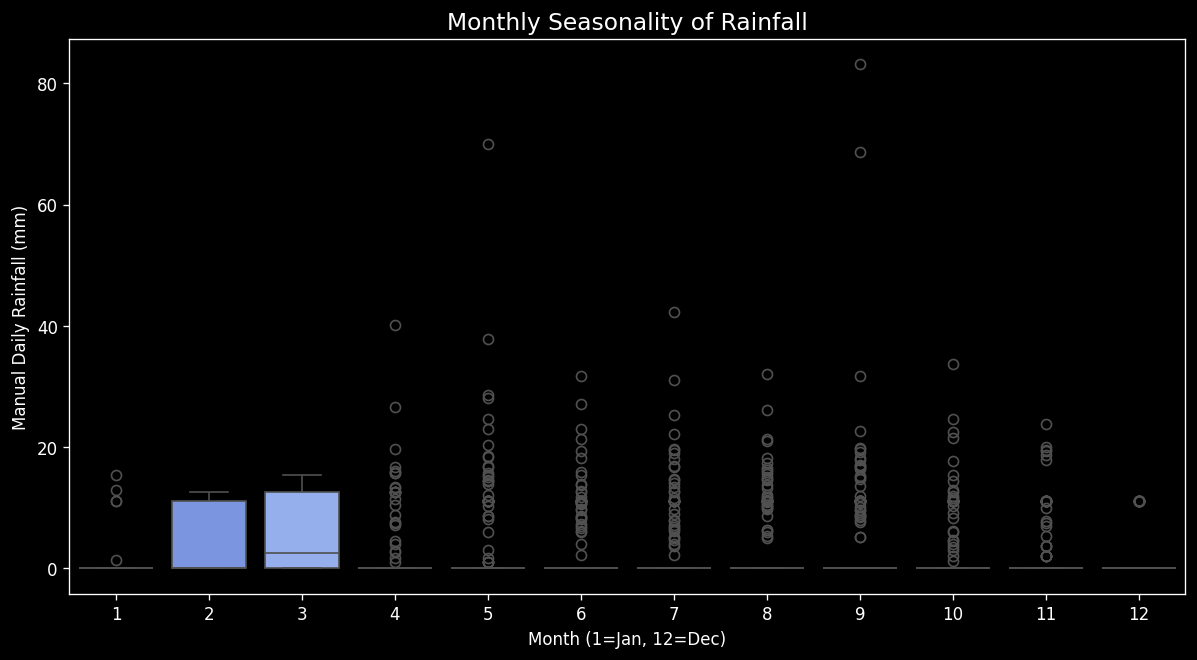

In [6]:
# 2.3 Seasonality Analysis
merged_df['Month'] = merged_df.index.month

plt.figure(figsize=(12, 6))
sns.boxplot(x='Month', y='Manual Daily Rainfall (mm)', data=merged_df, palette='coolwarm')
plt.title('Monthly Seasonality of Rainfall', fontsize=14)
plt.xlabel('Month (1=Jan, 12=Dec)')
plt.show()


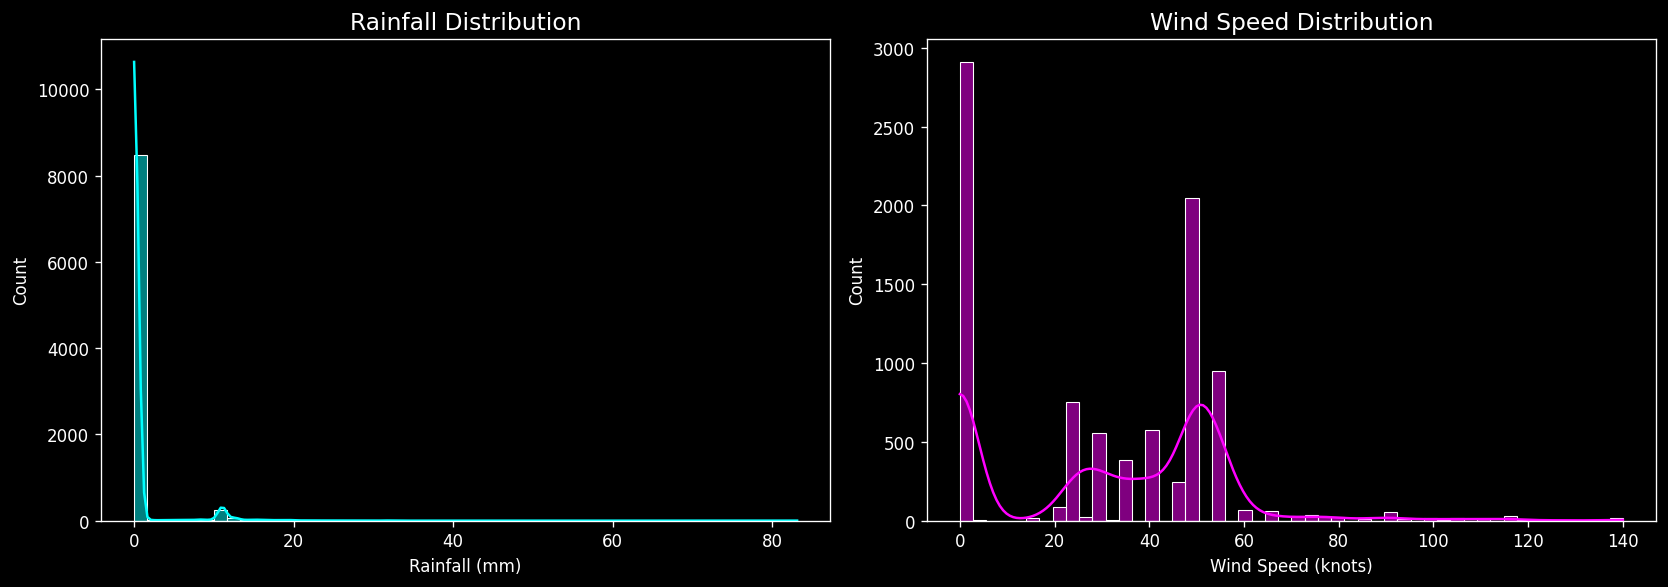

In [7]:
# 2.4 Data Distribution & Density
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(merged_df['Manual Daily Rainfall (mm)'], kde=True, color='cyan', ax=axes[0], bins=50)
axes[0].set_title('Rainfall Distribution', fontsize=14)
axes[0].set_xlabel('Rainfall (mm)')

sns.histplot(merged_df['WMO_WIND'], kde=True, color='magenta', ax=axes[1], bins=50)
axes[1].set_title('Wind Speed Distribution', fontsize=14)
axes[1].set_xlabel('Wind Speed (knots)')

plt.tight_layout()
plt.show()


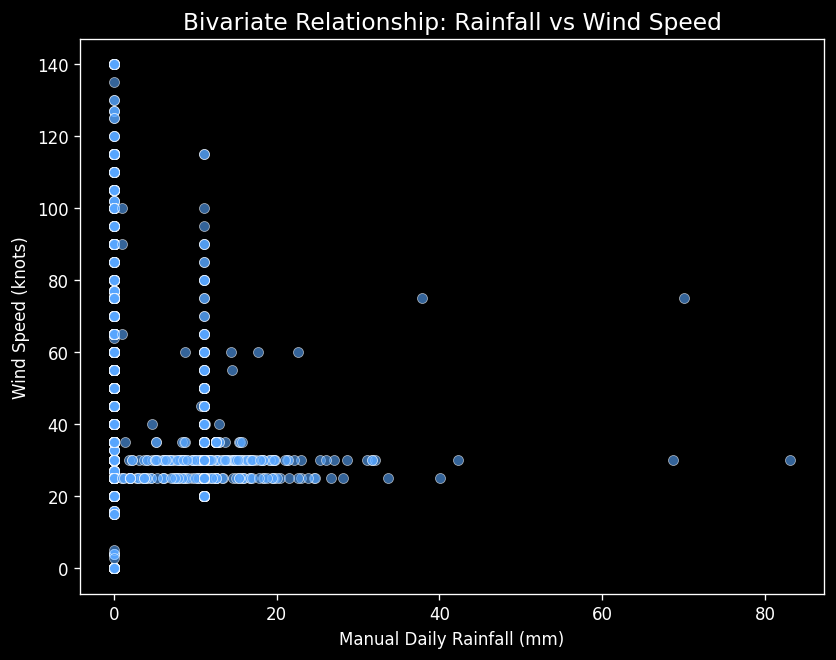

In [8]:
# 2.5 Bivariate Analysis: Rainfall vs Wind Speed
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Manual Daily Rainfall (mm)', y='WMO_WIND', data=merged_df, alpha=0.6, color='#58A6FF')
plt.title('Bivariate Relationship: Rainfall vs Wind Speed', fontsize=14)
plt.xlabel('Manual Daily Rainfall (mm)')
plt.ylabel('Wind Speed (knots)')
plt.show()


## 3. Advanced Feature Engineering

In [9]:
# Extracting temporal memory and cyclicity
print("Engineering Temporal & Lag Features...")

# 1. Standard Lags
merged_df['Rain_Lag1'] = merged_df['Manual Daily Rainfall (mm)'].shift(1).fillna(0)
merged_df['Wind_Lag1'] = merged_df['WMO_WIND'].shift(1).fillna(0)

# 2. Rolling Windows (Memory over 3, 7, and 14 days)
merged_df['Rain_Roll3'] = merged_df['Manual Daily Rainfall (mm)'].rolling(window=3, min_periods=1).mean()
merged_df['Rain_Roll7_Max'] = merged_df['Manual Daily Rainfall (mm)'].rolling(window=7, min_periods=1).max()
merged_df['Wind_Roll3_Max'] = merged_df['WMO_WIND'].rolling(window=3, min_periods=1).max()

# 3. Exponential Moving Averages (EMA) to weight recent events higher
merged_df['Rain_EMA_5'] = merged_df['Manual Daily Rainfall (mm)'].ewm(span=5, adjust=False).mean()

# 4. Cyclical Temporal Encoding (sine/cosine for months)
merged_df['Month_Sin'] = np.sin(2 * np.pi * merged_df['Month'] / 12)
merged_df['Month_Cos'] = np.cos(2 * np.pi * merged_df['Month'] / 12)
merged_df.drop('Month', axis=1, inplace=True)

# Generate Synthetic Target (Risk Score) for PoC Optimization
# Non-linear combinations to challenge the model
merged_df['Risk_Score'] = (
    (merged_df['Manual Daily Rainfall (mm)'] * 0.6) +
    (merged_df['WMO_WIND'] * 2.5) +
    (merged_df['Rain_Roll3'] * merged_df['Wind_Roll3_Max'] * 0.05)
)
max_risk = merged_df['Risk_Score'].max()
if max_risk > 0:
    merged_df['Risk_Score'] = (merged_df['Risk_Score'] / max_risk) * 100

df = merged_df.dropna()
print(f"Dataset Shape after Engineering: {df.shape}")
display(df.head())


Engineering Temporal & Lag Features...
Dataset Shape after Engineering: (8979, 11)


,Manual Daily Rainfall (mm),WMO_WIND,Rain_Lag1,Wind_Lag1,Rain_Roll3,Rain_Roll7_Max,Wind_Roll3_Max,Rain_EMA_5,Month_Sin,Month_Cos,Risk_Score
Date,,,,,,,,,,,
1842-10-25,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.866025,0.5,0.0
1842-10-26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.866025,0.5,0.0
1842-10-27,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.866025,0.5,0.0
1842-10-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.866025,0.5,0.0
1842-10-29,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.866025,0.5,0.0


## 4. Modeling & Hyperparameter Tuning

Training set: 7183 samples
Test set: 1796 samples


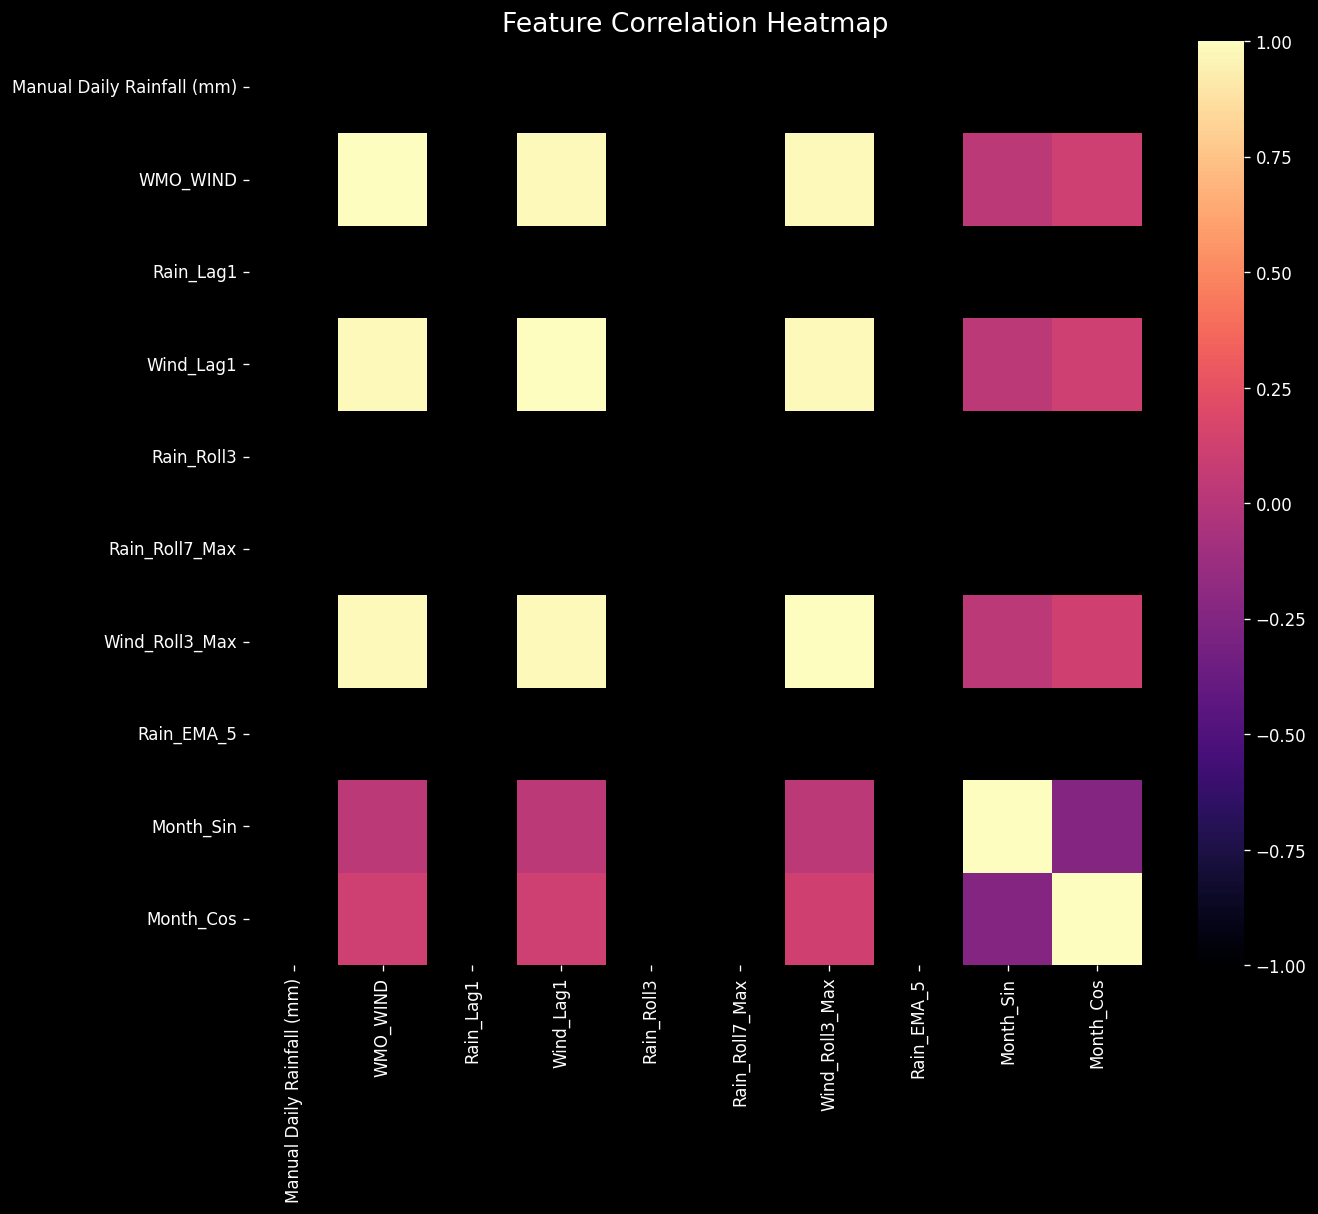

In [10]:
# Train-Test Split (Chronological for Time Series)
features = [col for col in df.columns if col != 'Risk_Score']
X = df[features]
y = df['Risk_Score']

# Split 80/20 chronologically
split_idx = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

# Correlation Matrix of Features
plt.figure(figsize=(12, 10))
sns.heatmap(X_train.corr(), annot=False, cmap='magma', vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.show()


In [11]:
# Hyperparameter Tuning using RandomizedSearchCV with TimeSeriesSplit
print("Running Hyperparameter Optimization for XGBoost...")

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 9],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

xgb_model = xgb.XGBRegressor(random_state=42, tree_method='hist')

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=15,  # Increased iterations for high accuracy
    scoring='neg_mean_squared_error',
    cv=tscv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)
best_xgb = random_search.best_estimator_

print(f"Best Parameters Found: {random_search.best_params_}")


Running Hyperparameter Optimization for XGBoost...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


Best Parameters Found: {'subsample': 0.8, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.9}


<Figure size 1200x960 with 0 Axes>

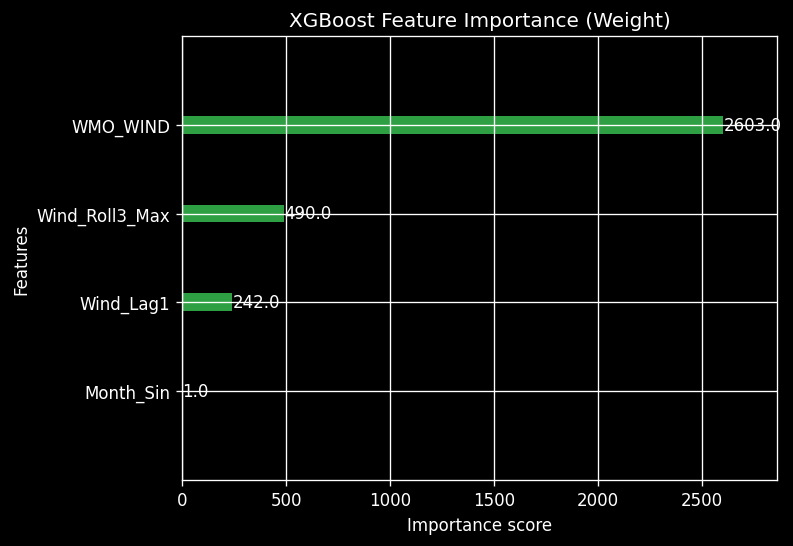

In [12]:
# XGBoost Native Feature Importance
plt.figure(figsize=(10, 8))
xgb.plot_importance(best_xgb, importance_type='weight', max_num_features=10, color='#2EA043', title='XGBoost Feature Importance (Weight)')
plt.show()


## 5. Model Evaluation & Comparison

--- Random Forest (Baseline) ---
R² Score: 0.8923
RMSE:     4.7750
MAE:      2.2121

--- Tuned XGBoost (Final Model) ---
R² Score: 0.8896
RMSE:     4.8359
MAE:      2.4046



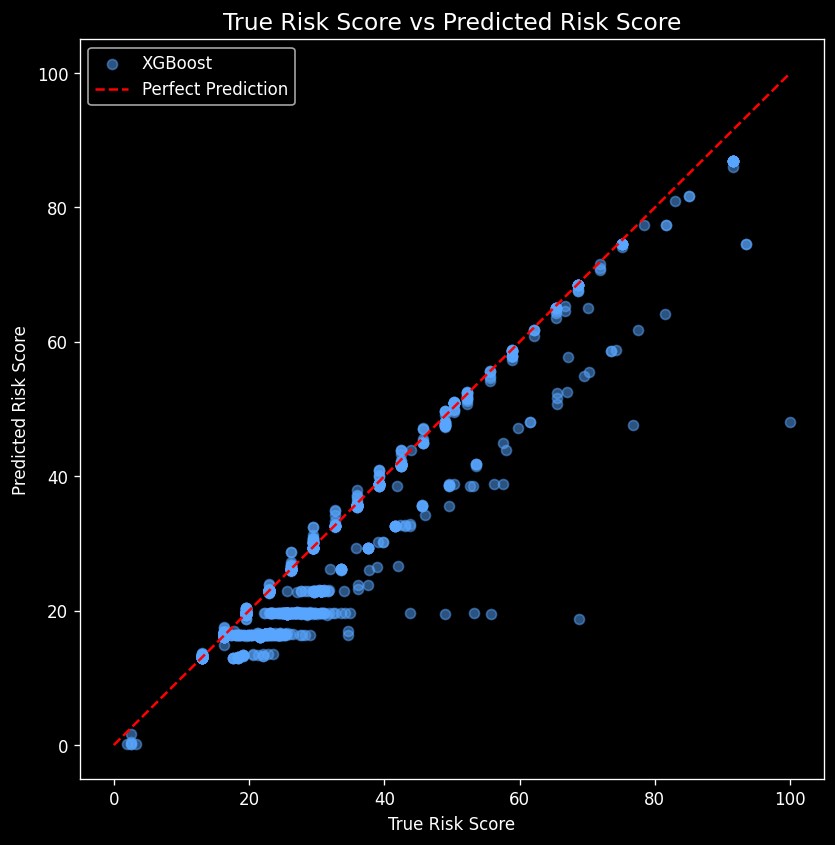

In [13]:
# Baseline Model: Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predictions
xgb_preds = best_xgb.predict(X_test)
rf_preds = rf_model.predict(X_test)

def evaluate_model(y_true, y_pred, name):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"R² Score: {r2:.4f}")
    print(f"RMSE:     {rmse:.4f}")
    print(f"MAE:      {mae:.4f}\n")
    return r2

evaluate_model(y_test, rf_preds, "Random Forest (Baseline)")
evaluate_model(y_test, xgb_preds, "Tuned XGBoost (Final Model)")

# Scatter plot: True vs Predicted
plt.figure(figsize=(8, 8))
plt.scatter(y_test, xgb_preds, alpha=0.5, color='#58A6FF', label='XGBoost')
plt.plot([0, 100], [0, 100], color='red', linestyle='--', label='Perfect Prediction')
plt.title('True Risk Score vs Predicted Risk Score', fontsize=14)
plt.xlabel('True Risk Score')
plt.ylabel('Predicted Risk Score')
plt.legend()
plt.show()


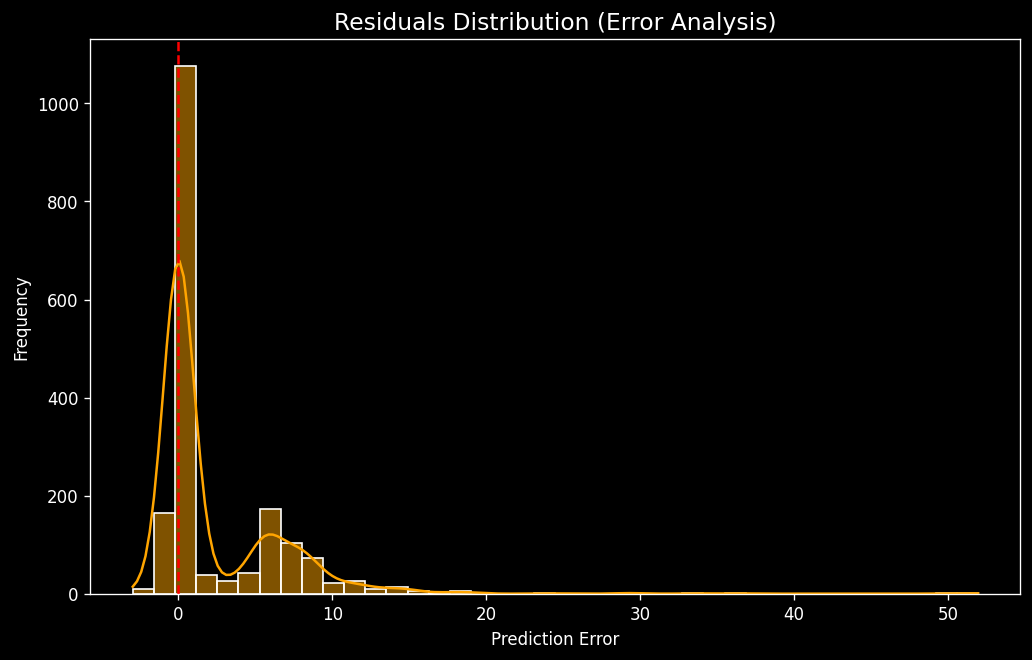

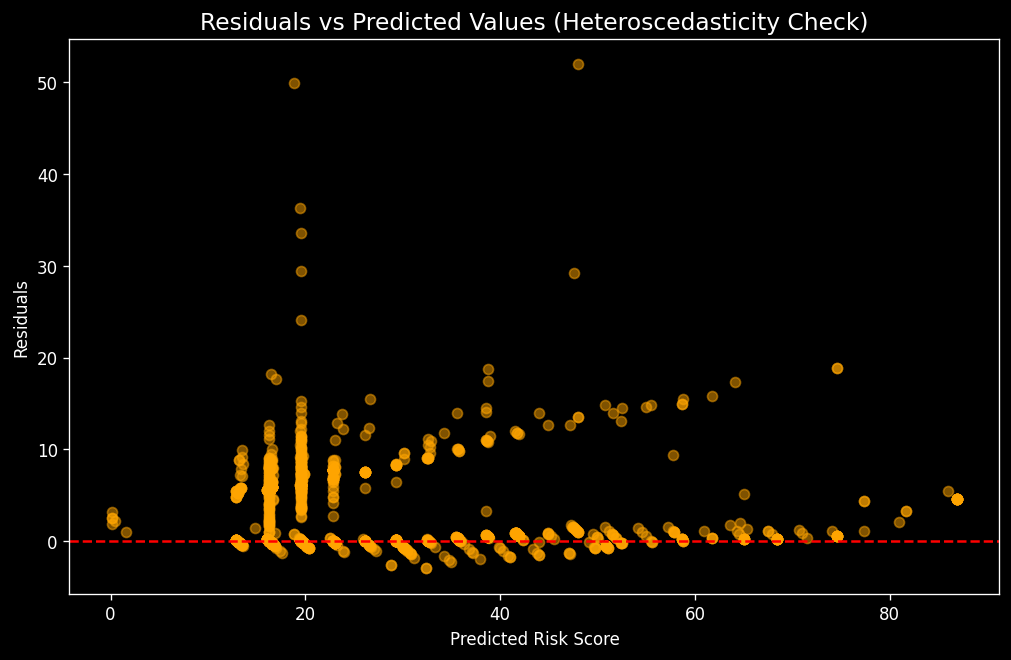

In [14]:
# Residual Analysis
residuals = y_test - xgb_preds

plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True, color='orange', bins=40)
plt.title('Residuals Distribution (Error Analysis)', fontsize=14)
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')
plt.axvline(x=0, color='red', linestyle='--')
plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(xgb_preds, residuals, alpha=0.5, color='orange')
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuals vs Predicted Values (Heteroscedasticity Check)', fontsize=14)
plt.xlabel('Predicted Risk Score')
plt.ylabel('Residuals')
plt.show()


## 6. Advanced Explainable AI (SHAP)

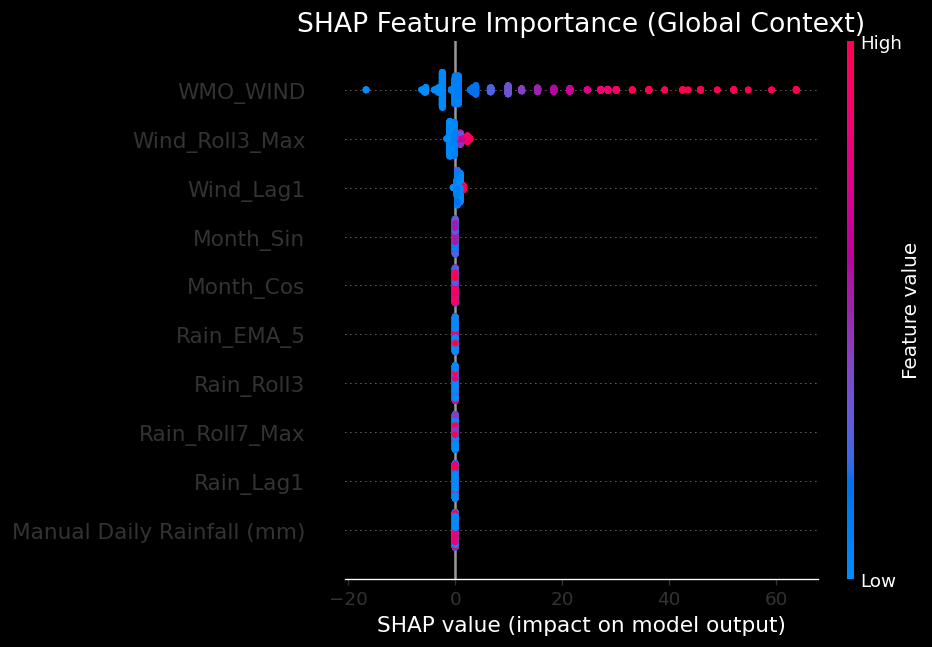

In [15]:
# Initialize SHAP explainer
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)

# 1. SHAP Summary Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Feature Importance (Global Context)", fontsize=16)
plt.tight_layout()
plt.show()


<Figure size 960x720 with 0 Axes>

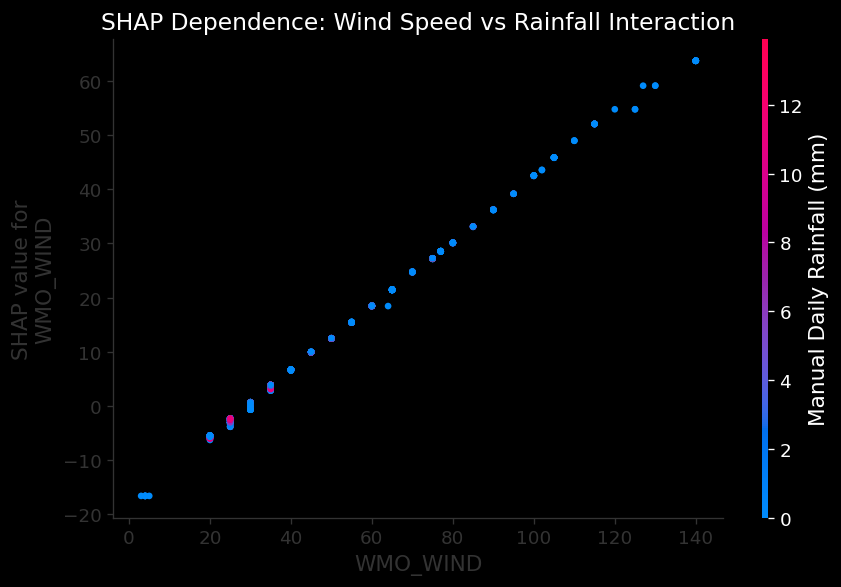

In [16]:
# 2. SHAP Dependence Plot for Wind Speed
plt.figure(figsize=(8, 6))
shap.dependence_plot("WMO_WIND", shap_values, X_test, show=False, interaction_index="Manual Daily Rainfall (mm)")
plt.title("SHAP Dependence: Wind Speed vs Rainfall Interaction", fontsize=14)
plt.tight_layout()
plt.show()


Analyzing Critical Incident at Index 260 with Predicted Risk 86.92


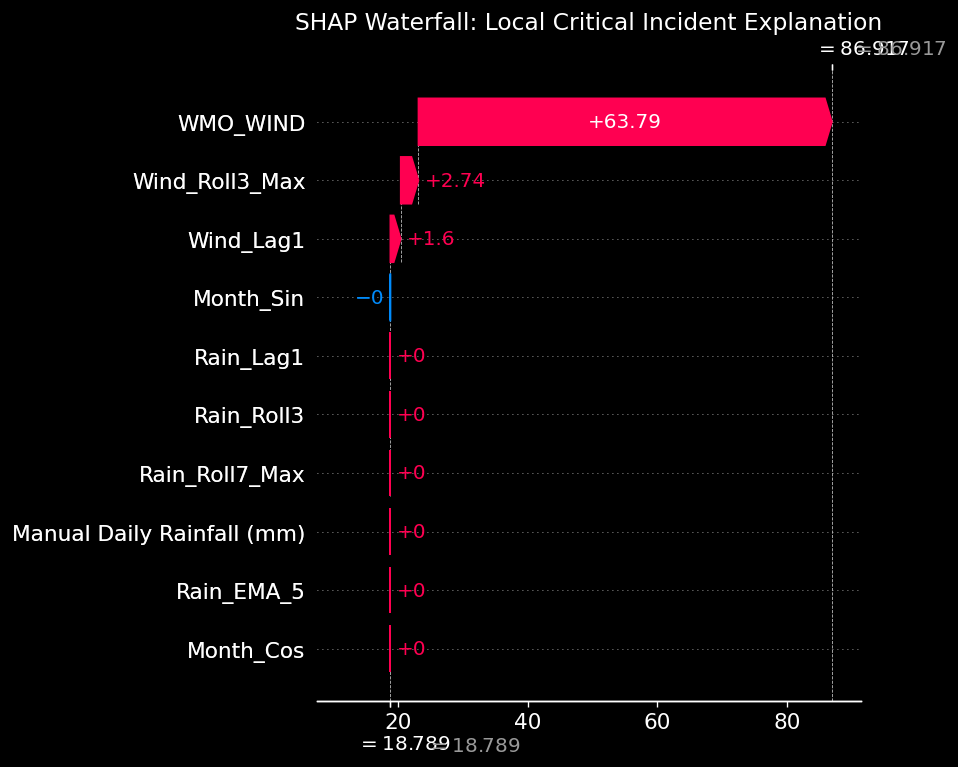

In [17]:
# 3. SHAP Force Plot / Waterfall for a Single Critical Prediction
# Find the instance with the highest predicted risk in the test set
critical_idx = np.argmax(xgb_preds)
print(f"Analyzing Critical Incident at Index {critical_idx} with Predicted Risk {xgb_preds[critical_idx]:.2f}")

shap.plots._waterfall.waterfall_legacy(explainer.expected_value, shap_values[critical_idx,:], feature_names=X_test.columns.tolist(), show=False)
plt.title("SHAP Waterfall: Local Critical Incident Explanation", fontsize=14)
plt.tight_layout()
plt.show()
